In [ ]:
# Libreria para cargar nuestro drive
from google.colab import drive
# Cargamos nuestro drive en nuestro notebook
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
# Ajusta esta ruta a la carpeta de Drive donde guardas los datos del proyecto.
PROJECT_DIR = "/content/drive/MyDrive/plant-disease-classification"

In [ ]:
import os
import shutil

src = os.path.join(PROJECT_DIR, "PlantVillage")
dst = "/content/PlantVillage"

if not os.path.exists(dst):
    shutil.copytree(src, dst)
    print("✅ Dataset copiado a /content")
else:
    print("⚠️ Ya existe en /content")

⚠️ Ya existe en /content


In [ ]:
import os

total = 0
for folder in os.listdir("/content/PlantVillage"):
    folder_path = os.path.join("/content/PlantVillage", folder)
    if os.path.isdir(folder_path):
        total += len(os.listdir(folder_path))

print("Total imágenes:", total)

Total imágenes: 20639


In [ ]:
import tensorflow as tf
import numpy as np
import random

seed = 42

tf.random.set_seed(seed)
np.random.seed(seed)
random.seed(seed)

In [ ]:
import pandas as pd
import os

# Ruta principal del dataset (cada carpeta es una clase)
path_raiz = "/content/PlantVillage"

# Listas para guardar rutas de imágenes y sus etiquetas
filepaths = []
labels = []

# Recorremos cada carpeta (clase)
classlist = sorted(os.listdir(path_raiz))
for klass in classlist:
    classpath = os.path.join(path_raiz, klass)

    # Verificamos que sea una carpeta válida
    if os.path.isdir(classpath):
        flist = os.listdir(classpath)

        # Recorremos cada archivo dentro de la carpeta
        for f in flist:
            # Filtramos solo archivos de imagen
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                fpath = os.path.join(classpath, f)

                # Guardamos la ruta y la etiqueta (nombre de la carpeta)
                filepaths.append(fpath)
                labels.append(klass)

# Creamos el DataFrame con rutas y etiquetas
df = pd.DataFrame({'filepaths': filepaths, 'labels': labels})

# Mostramos información general del dataset
print(f"✅ DataFrame creado con éxito.")
print(f"Total de imágenes registradas: {len(df)}")

# Conteo por clase (útil para ver desbalanceo)
print("\nConteo por clase (aquí verás el desbalanceo):")
print(df['labels'].value_counts())


✅ DataFrame creado con éxito.
Total de imágenes registradas: 20638

Conteo por clase (aquí verás el desbalanceo):
labels
Tomato__Tomato_YellowLeaf__Curl_Virus          3208
Tomato_Bacterial_spot                          2127
Tomato_Late_blight                             1909
Tomato_Septoria_leaf_spot                      1771
Tomato_Spider_mites_Two_spotted_spider_mite    1676
Tomato_healthy                                 1591
Pepper__bell___healthy                         1478
Tomato__Target_Spot                            1404
Potato___Early_blight                          1000
Potato___Late_blight                           1000
Tomato_Early_blight                            1000
Pepper__bell___Bacterial_spot                   997
Tomato_Leaf_Mold                                952
Tomato__Tomato_mosaic_virus                     373
Potato___healthy                                152
Name: count, dtype: int64


In [ ]:
sample_list = []
max_size = 500

groups = df.groupby('labels')

for label in df['labels'].unique():
    group = groups.get_group(label)
    sample_count = len(group)

    if sample_count > max_size:
        samples = group.sample(max_size, random_state=42).reset_index(drop=True)
    else:
        samples = group.sample(frac=1.0, random_state=42).reset_index(drop=True)

    sample_list.append(samples)

df = pd.concat(sample_list, axis=0).reset_index(drop=True)

print(df['labels'].value_counts())

labels
Pepper__bell___Bacterial_spot                  500
Pepper__bell___healthy                         500
Potato___Early_blight                          500
Potato___Late_blight                           500
Tomato_Bacterial_spot                          500
Tomato_Early_blight                            500
Tomato_Late_blight                             500
Tomato__Target_Spot                            500
Tomato_Leaf_Mold                               500
Tomato_Septoria_leaf_spot                      500
Tomato_Spider_mites_Two_spotted_spider_mite    500
Tomato_healthy                                 500
Tomato__Tomato_YellowLeaf__Curl_Virus          500
Tomato__Tomato_mosaic_virus                    373
Potato___healthy                               152
Name: count, dtype: int64


In [ ]:
import shutil

aug_dir = '/content/aug'

if os.path.exists(aug_dir):
    shutil.rmtree(aug_dir)

os.mkdir(aug_dir)

for label in df['labels'].unique():
    os.mkdir(os.path.join(aug_dir, label))

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

target = 500

gen = ImageDataGenerator(
    horizontal_flip=True,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    zoom_range=0.2
)

groups = df.groupby('labels')

for label in df['labels'].unique():
    group = groups.get_group(label)
    sample_count = len(group)

    if sample_count < target:
        delta = target - sample_count
        target_dir = os.path.join(aug_dir, label)

        aug_gen = gen.flow_from_dataframe(
            group,
            x_col='filepaths',
            y_col=None,
            target_size=(224, 224),
            class_mode=None,
            batch_size=1,
            shuffle=False,
            save_to_dir=target_dir,
            save_prefix='aug-',
            save_format='jpg'
        )

        count = 0
        while count < delta:
            images = next(aug_gen)
            count += len(images)

Found 152 validated image filenames.


In [ ]:
aug_fpaths = []
aug_labels = []

for label in os.listdir(aug_dir):
    classpath = os.path.join(aug_dir, label)

    for f in os.listdir(classpath):
        aug_fpaths.append(os.path.join(classpath, f))
        aug_labels.append(label)

aug_df = pd.DataFrame({
    'filepaths': aug_fpaths,
    'labels': aug_labels
})

In [ ]:
ndf = pd.concat([df, aug_df], axis=0).reset_index(drop=True)

print(ndf['labels'].value_counts())

labels
Pepper__bell___Bacterial_spot                  500
Pepper__bell___healthy                         500
Potato___Early_blight                          500
Potato___Late_blight                           500
Potato___healthy                               500
Tomato_Bacterial_spot                          500
Tomato_Early_blight                            500
Tomato_Late_blight                             500
Tomato_Leaf_Mold                               500
Tomato_Septoria_leaf_spot                      500
Tomato_Spider_mites_Two_spotted_spider_mite    500
Tomato__Target_Spot                            500
Tomato__Tomato_YellowLeaf__Curl_Virus          500
Tomato__Tomato_mosaic_virus                    500
Tomato_healthy                                 500
Name: count, dtype: int64


In [ ]:
counts = ndf['labels'].value_counts()

print(counts)
print("\nMin:", counts.min(), "Max:", counts.max())

labels
Pepper__bell___Bacterial_spot                  500
Pepper__bell___healthy                         500
Potato___Early_blight                          500
Potato___Late_blight                           500
Potato___healthy                               500
Tomato_Bacterial_spot                          500
Tomato_Early_blight                            500
Tomato_Late_blight                             500
Tomato_Leaf_Mold                               500
Tomato_Septoria_leaf_spot                      500
Tomato_Spider_mites_Two_spotted_spider_mite    500
Tomato__Target_Spot                            500
Tomato__Tomato_YellowLeaf__Curl_Virus          500
Tomato__Tomato_mosaic_virus                    500
Tomato_healthy                                 500
Name: count, dtype: int64

Min: 500 Max: 500


In [ ]:
# Utilizar para generar el archivo ndf_final.csv y utilizar en notebook 04
drive_aug_dir = os.path.join(PROJECT_DIR, "aug")

shutil.copytree(aug_dir, drive_aug_dir, dirs_exist_ok=True)

ndf_to_save = ndf.copy()
ndf_to_save["filepaths"] = (
    ndf_to_save["filepaths"]
    .str.replace(
        "/content/PlantVillage",
        os.path.join(PROJECT_DIR, "PlantVillage"),
        regex=False,
    )
    .str.replace(
        "/content/aug",
        drive_aug_dir,
        regex=False,
    )
)

csv_path = os.path.join(PROJECT_DIR, "ndf_final.csv")
ndf_to_save.to_csv(csv_path, index=False)

print(f"Saved dataset manifest to: {csv_path}")
print(f"Saved augmented images to: {drive_aug_dir}")

In [ ]:
import matplotlib.pyplot as plt

counts = ndf['labels'].value_counts().sort_index()

plt.figure(figsize=(12,5))
counts.plot(kind='bar')

plt.title("Distribución de clases (dataset balanceado)")
plt.xlabel("Clases")
plt.ylabel("Número de imágenes")
plt.xticks(rotation=90)

plt.show()

![Balanced class distribution](../images/balanced_class_distribution.png)

In [ ]:
from sklearn.model_selection import train_test_split

# 80% train, 20% temporal
train_df, temp_df = train_test_split(
    ndf,
    test_size=0.2,
    stratify=ndf['labels'],
    random_state=42
)

# 10% val, 10% test
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    stratify=temp_df['labels'],
    random_state=42
)

print("TRAIN:\n", train_df['labels'].value_counts())
print("\nVAL:\n", val_df['labels'].value_counts())
print("\nTEST:\n", test_df['labels'].value_counts())

TRAIN:
 labels
Tomato__Tomato_YellowLeaf__Curl_Virus          400
Tomato_Leaf_Mold                               400
Tomato__Target_Spot                            400
Tomato_healthy                                 400
Potato___Late_blight                           400
Potato___Early_blight                          400
Tomato_Bacterial_spot                          400
Pepper__bell___Bacterial_spot                  400
Tomato_Late_blight                             400
Tomato_Septoria_leaf_spot                      400
Potato___healthy                               400
Tomato__Tomato_mosaic_virus                    400
Tomato_Spider_mites_Two_spotted_spider_mite    400
Tomato_Early_blight                            400
Pepper__bell___healthy                         400
Name: count, dtype: int64

VAL:
 labels
Tomato__Tomato_mosaic_virus                    50
Tomato_Bacterial_spot                          50
Tomato__Tomato_YellowLeaf__Curl_Virus          50
Tomato_Spider_mites_Two_spotte

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(rescale=1./255)
val_datagen = ImageDataGenerator(rescale=1./255)

train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False,
    seed=42
)

test_generator = val_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

Found 6000 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout, BatchNormalization, Input

num_classes = len(train_generator.class_indices)

model = Sequential()

# Entrada
model.add(Input(shape=(224,224,3)))

# Bloque 1
model.add(Conv2D(32, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 2
model.add(Conv2D(64, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 3
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(BatchNormalization())
model.add(MaxPooling2D(2,2))

# Bloque 4
model.add(Conv2D(256, (3,3), activation='relu'))
model.add(MaxPooling2D(2,2))

# Aplanar
model.add(Flatten())

# Capa densa
model.add(Dense(256, activation='relu'))
model.add(Dropout(0.5))

# Salida
model.add(Dense(num_classes, activation='softmax'))

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 222, 222, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 109, 109, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 52, 52, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 24, 24, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 36864)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │     9,437,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,830,607 (37.50 MB)

 Trainable params: 9,830,159 (37.50 MB)

 Non-trainable params: 448 (1.75 KB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 34s 142ms/step - accuracy: 0.4087 - loss: 2.5228 - val_accuracy: 0.0667 - val_loss: 15.2150
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 82ms/step - accuracy: 0.5902 - loss: 1.3117 - val_accuracy: 0.1320 - val_loss: 7.2021
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.6772 - loss: 1.0068 - val_accuracy: 0.5933 - val_loss: 1.2799
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 16s 84ms/step - accuracy: 0.7297 - loss: 0.8402 - val_accuracy: 0.5040 - val_loss: 2.1739
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - accuracy: 0.7542 - loss: 0.7772 - val_accuracy: 0.4280 - val_loss: 2.3909
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 79ms/step - accuracy: 0.7833 - loss: 0.6765 - val_accuracy: 0.8080 - val_loss: 0.6036
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 80ms/step - accuracy: 0.8220 - loss: 0.5497 - val_accuracy: 0.3240 - val_loss: 7.3365
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 15s 81ms/step - accuracy: 0.8413 - loss: 0.4930 

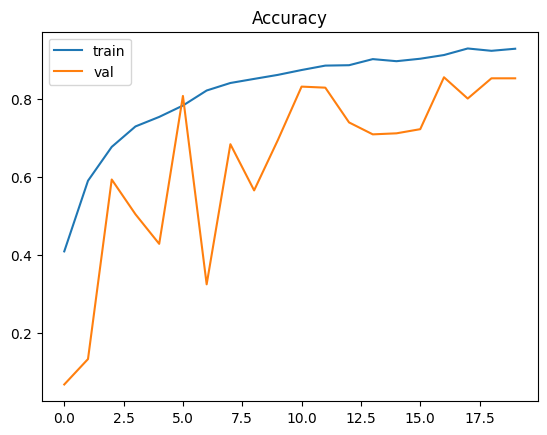

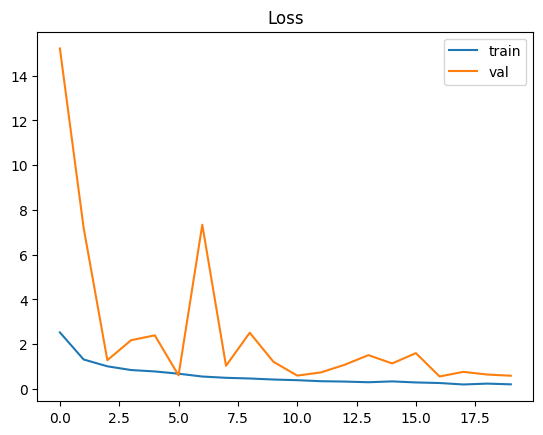

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
loss, acc = model.evaluate(test_generator)

print(f"Test Loss: {loss}")
print(f"Test Accuracy: {acc}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 64ms/step - accuracy: 0.8613 - loss: 0.5203
Test Loss: 0.5203434824943542
Test Accuracy: 0.8613333106040955


In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 70ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

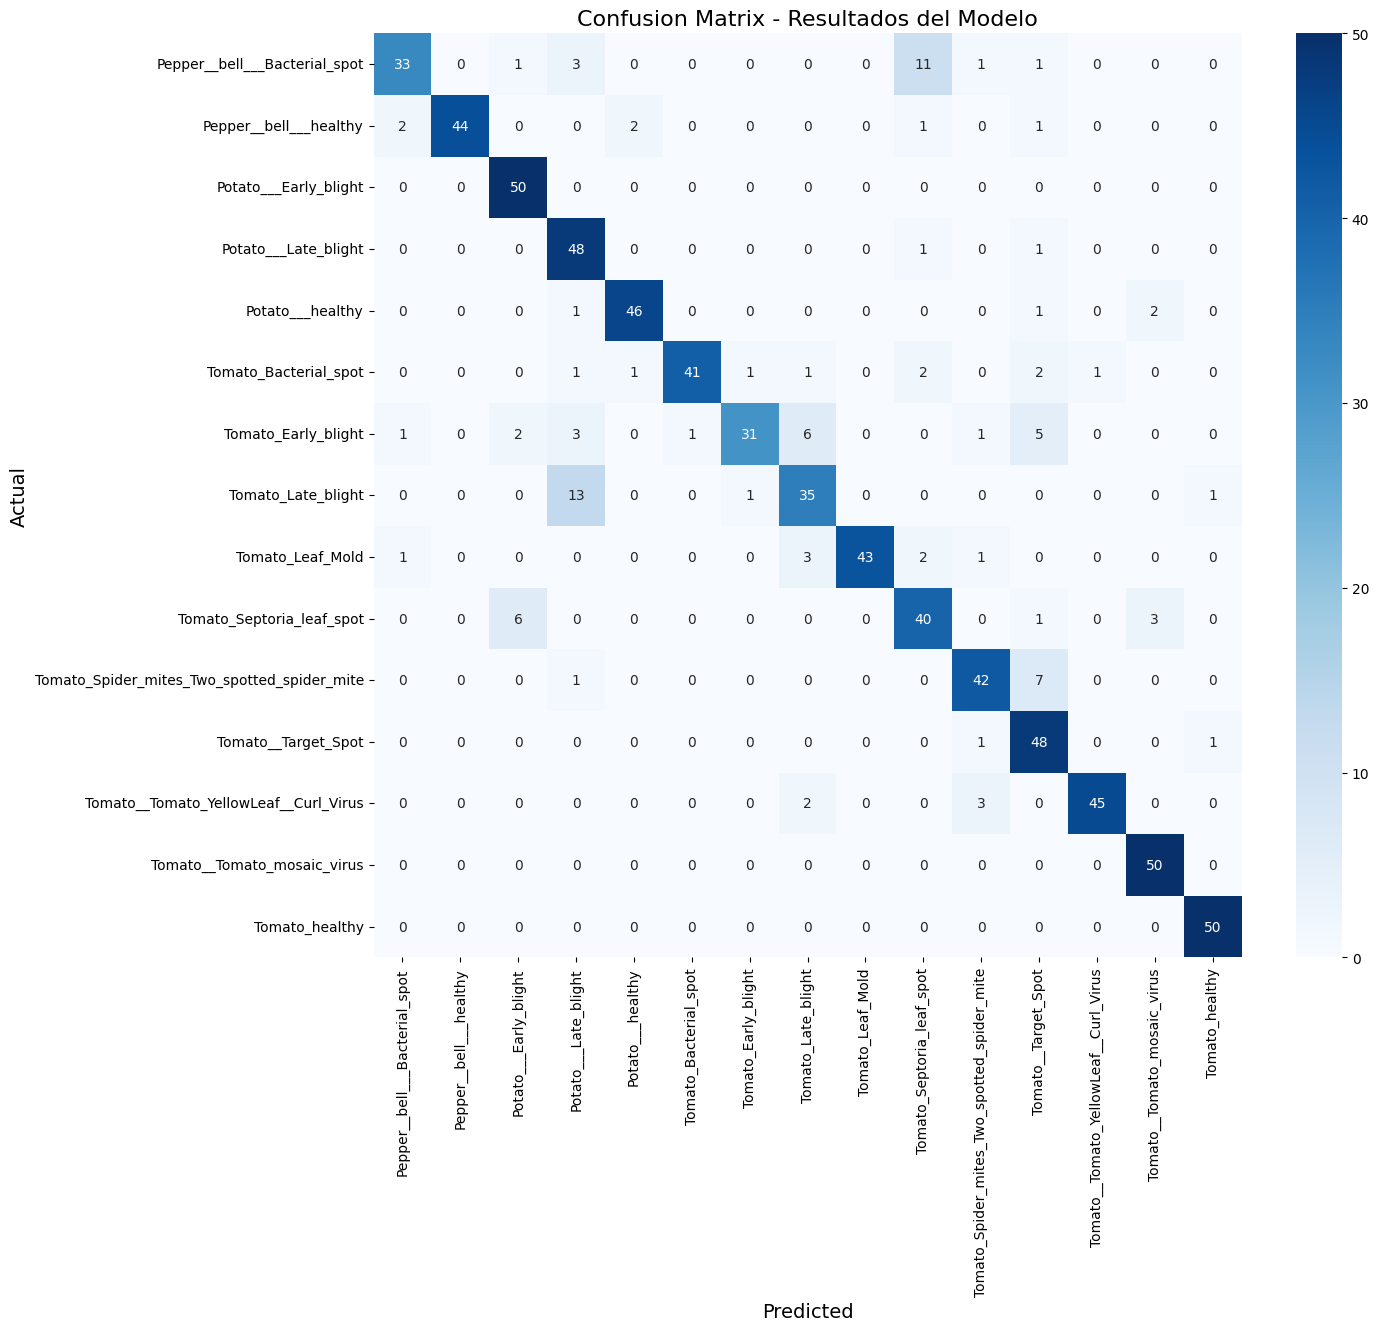

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generamos la matriz
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 10})

plt.xlabel("Predicted", fontsize=14)
plt.ylabel("Actual", fontsize=14)
plt.title("Confusion Matrix - Resultados del Modelo", fontsize=16)
plt.xticks(rotation=90) # Rota las etiquetas para que se lean bien
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.89      0.66      0.76        50
                     Pepper__bell___healthy       1.00      0.88      0.94        50
                      Potato___Early_blight       0.85      1.00      0.92        50
                       Potato___Late_blight       0.69      0.96      0.80        50
                           Potato___healthy       0.94      0.92      0.93        50
                      Tomato_Bacterial_spot       0.98      0.82      0.89        50
                        Tomato_Early_blight       0.94      0.62      0.75        50
                         Tomato_Late_blight       0.74      0.70      0.72        50
                           Tomato_Leaf_Mold       1.00      0.86      0.92        50
                  Tomato_Septoria_leaf_spot       0.70      0.80      0.75        50
Tomato_Spider_mites_Two_spotted_spider_mite       0.86      0.84

## 🔬 Experimento 2: Modelo DenseNet121

In [ ]:
IMG_SIZE = 224

In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import DenseNet121
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout
from tensorflow.keras.models import Model

# Cargar modelo base (sin la parte final)
base_model = DenseNet121(
    weights='imagenet',
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

for layer in base_model.layers:
    layer.trainable = False


x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(len(train_generator.class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()

29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "functional_30"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d      │ (None, 230, 230,  │          0 │ input_layer_2[0]… │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,408 │ zero_padding2d[0… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ zero_padding2d_1    │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1               │ (None, 56, 56,    │          0 │ zero_padding2d_1… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │        256 │ pool1[0][0]       │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_relu │ (None, 56, 56,    │          0 │ conv2_block1_0_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      8,192 │ conv2_block1_0_r… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        512 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,864 │ conv2_block1_1_r… │
│ (Conv2D)            │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_concat │ (None, 56, 56,    │          0 │ pool1[0][0],      │
│ (Concatenate)       │ 96)               │            │ conv2_block1_2_c… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_bn   │ (None, 56, 56,    │        384 │ conv2_block1_con… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_0_relu │ (None, 56, 56,    │          0 │ conv2_block2_0_b… │
│ (Activation)        │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block2_1_conv │ (None, 56, 56,    │     12,288 │ conv2_block2_0_r

 Total params: 7,303,759 (27.86 MB)

 Trainable params: 266,255 (1.02 MB)

 Non-trainable params: 7,037,504 (26.85 MB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 97s 345ms/step - accuracy: 0.5348 - loss: 1.4681 - val_accuracy: 0.7800 - val_loss: 0.7319
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 103ms/step - accuracy: 0.7562 - loss: 0.7489 - val_accuracy: 0.8453 - val_loss: 0.5166
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 20s 104ms/step - accuracy: 0.8073 - loss: 0.5794 - val_accuracy: 0.8693 - val_loss: 0.4255
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 100ms/step - accuracy: 0.8427 - loss: 0.4788 - val_accuracy: 0.8680 - val_loss: 0.4249
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 99ms/step - accuracy: 0.8655 - loss: 0.4105 - val_accuracy: 0.8840 - val_loss: 0.3581
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 102ms/step - accuracy: 0.8785 - loss: 0.3765 - val_accuracy: 0.8920 - val_loss: 0.3437
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 102ms/step - accuracy: 0.8870 - loss: 0.3344 - val_accuracy: 0.9013 - val_loss: 0.3041
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 19s 99ms/step - accuracy: 0.8913 - loss: 0.3

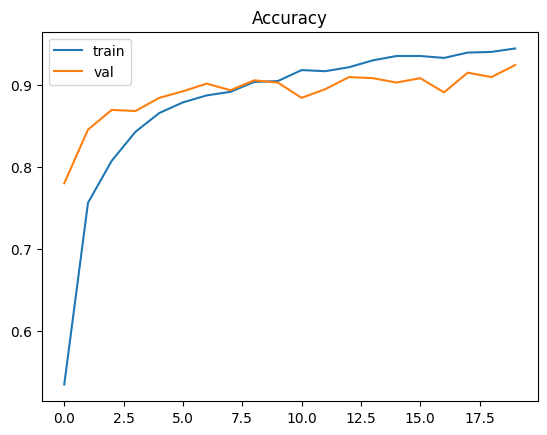

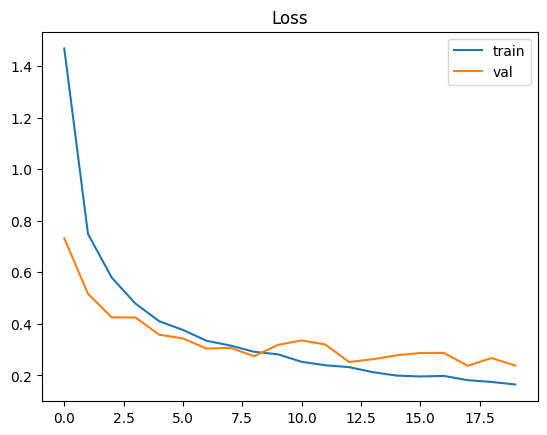

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test accuracy: {test_acc}")
print(f"Test loss: {test_loss}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.9333 - loss: 0.1908
Test accuracy: 0.9333333373069763
Test loss: 0.19082829356193542


In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

24/24 ━━━━━━━━━━━━━━━━━━━━ 40s 784ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

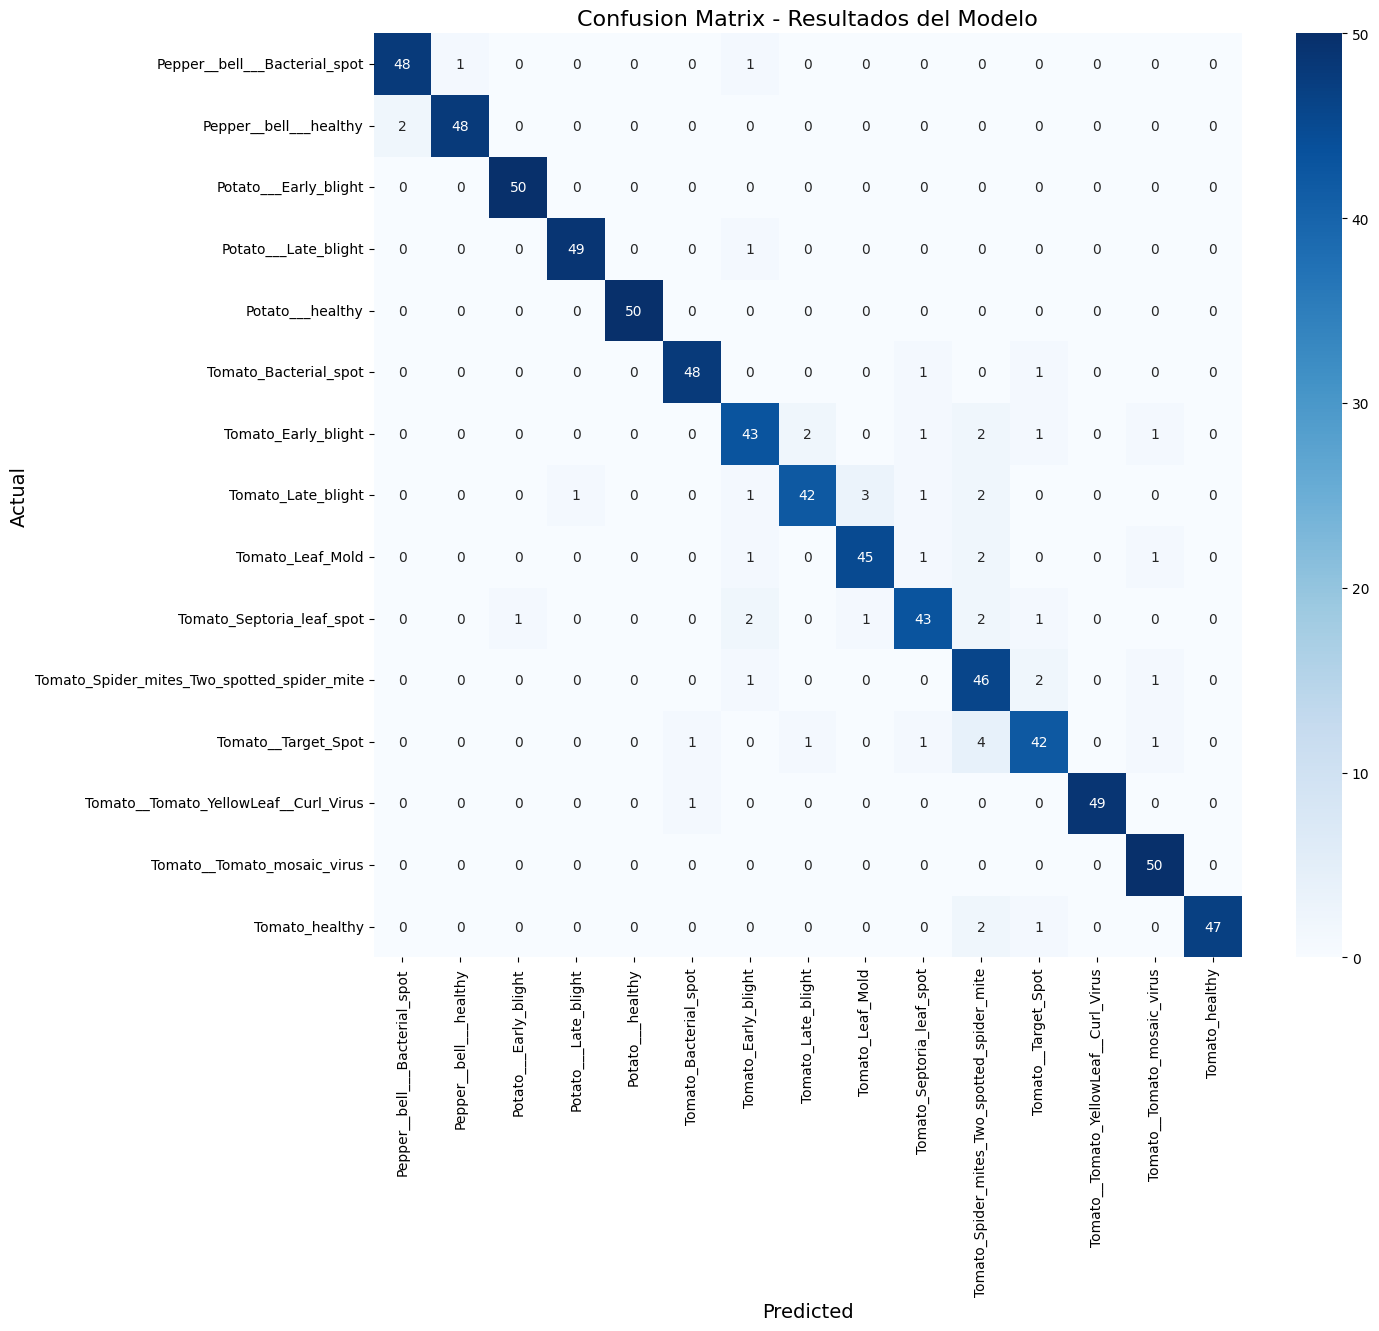

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generamos la matriz
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 10})

plt.xlabel("Predicted", fontsize=14)
plt.ylabel("Actual", fontsize=14)
plt.title("Confusion Matrix - Resultados del Modelo", fontsize=16)
plt.xticks(rotation=90) # Rota las etiquetas para que se lean bien
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.96      0.96      0.96        50
                     Pepper__bell___healthy       0.98      0.96      0.97        50
                      Potato___Early_blight       0.98      1.00      0.99        50
                       Potato___Late_blight       0.98      0.98      0.98        50
                           Potato___healthy       1.00      1.00      1.00        50
                      Tomato_Bacterial_spot       0.96      0.96      0.96        50
                        Tomato_Early_blight       0.86      0.86      0.86        50
                         Tomato_Late_blight       0.93      0.84      0.88        50
                           Tomato_Leaf_Mold       0.92      0.90      0.91        50
                  Tomato_Septoria_leaf_spot       0.90      0.86      0.88        50
Tomato_Spider_mites_Two_spotted_spider_mite       0.77      0.92

## 🔬 Experimento 3: Modelo EfficientNet

In [ ]:
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.05,
    height_shift_range=0.05,
    horizontal_flip=True
)

val_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

In [ ]:
train_generator = train_datagen.flow_from_dataframe(
    train_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=True,
    seed=42
)

val_generator = val_datagen.flow_from_dataframe(
    val_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False,
    seed=42
)

test_generator = val_datagen.flow_from_dataframe(
    test_df,
    x_col='filepaths',
    y_col='labels',
    target_size=(224,224),
    class_mode='categorical',
    batch_size=32,
    shuffle=False
)

Found 6000 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.
Found 750 validated image filenames belonging to 15 classes.


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, BatchNormalization
from tensorflow.keras.models import Model

# Modelo base
base_model = EfficientNetB0(
    weights='imagenet',
    include_top=False,
    input_shape=(224,224,3)
)

# Congelar capas
for layer in base_model.layers:
    layer.trainable = False

# Head
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = BatchNormalization()(x)

x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(len(train_generator.class_indices), activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)

model.summary()

Model: "functional_32"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_2         │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization_1     │ (None, 224, 224,  │          7 │ rescaling_2[0][0] │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ normalization_1[… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_3[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 4,386,482 (16.73 MB)

 Trainable params: 334,351 (1.28 MB)

 Non-trainable params: 4,052,131 (15.46 MB)

In [ ]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True
)

In [ ]:
history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=20,
    callbacks=[early_stop]
)

Epoch 1/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 137s 614ms/step - accuracy: 0.6880 - loss: 1.0023 - val_accuracy: 0.8547 - val_loss: 0.5092
Epoch 2/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 439ms/step - accuracy: 0.8502 - loss: 0.4716 - val_accuracy: 0.8800 - val_loss: 0.3393
Epoch 3/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 79s 421ms/step - accuracy: 0.8720 - loss: 0.3875 - val_accuracy: 0.8947 - val_loss: 0.3023
Epoch 4/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 85s 450ms/step - accuracy: 0.8902 - loss: 0.3130 - val_accuracy: 0.9027 - val_loss: 0.2523
Epoch 5/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 440ms/step - accuracy: 0.9093 - loss: 0.2846 - val_accuracy: 0.9160 - val_loss: 0.2789
Epoch 6/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 79s 421ms/step - accuracy: 0.9090 - loss: 0.2741 - val_accuracy: 0.9227 - val_loss: 0.2250
Epoch 7/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 78s 418ms/step - accuracy: 0.9180 - loss: 0.2489 - val_accuracy: 0.9133 - val_loss: 0.2538
Epoch 8/20
188/188 ━━━━━━━━━━━━━━━━━━━━ 79s 418ms/step - accuracy: 0.9237 - loss: 

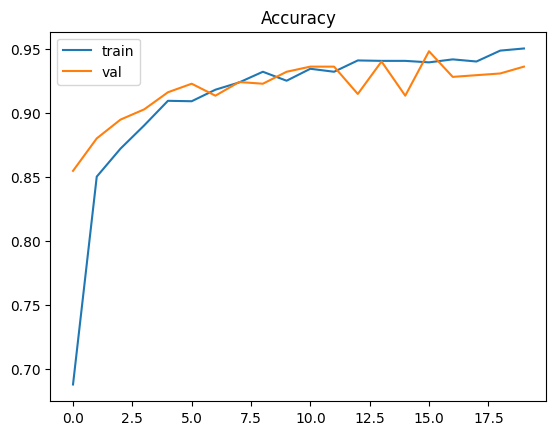

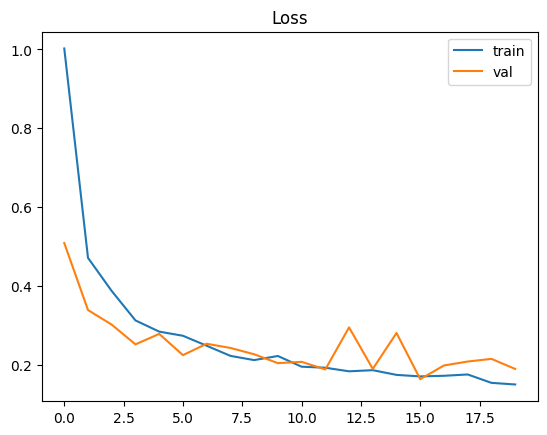

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test accuracy: {test_acc}")
print(f"Test loss: {test_loss}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 2s 63ms/step - accuracy: 0.9520 - loss: 0.1626
Test accuracy: 0.9520000219345093
Test loss: 0.162637859582901


In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

24/24 ━━━━━━━━━━━━━━━━━━━━ 16s 415ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       1.00      0.98      0.99        50
                     Pepper__bell___healthy       0.94      1.00      0.97        50
                      Potato___Early_blight       1.00      1.00      1.00        50
                       Potato___Late_blight       1.00      0.96      0.98        50
                           Potato___healthy       0.98      0.98      0.98        50
                      Tomato_Bacterial_spot       1.00      0.88      0.94        50
                        Tomato_Early_blight       0.93      0.80      0.86        50
                         Tomato_Late_blight       0.94      0.94      0.94        50
                           Tomato_Leaf_Mold       0.94      0.98      0.96        50
                  Tomato_Septoria_leaf_spot       0.84      0.98      0.91        50
Tomato_Spider_mites_Two_spotted_spider_mite       0.98      0.96

In [ ]:
# Descongelar últimas capas
for layer in base_model.layers[-50:]:
    layer.trainable = True

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history_fine = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=10,
    callbacks=[early_stop]
)

Epoch 1/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 149s 602ms/step - accuracy: 0.8582 - loss: 0.5902 - val_accuracy: 0.9053 - val_loss: 0.3909
Epoch 2/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 444ms/step - accuracy: 0.9223 - loss: 0.2907 - val_accuracy: 0.9200 - val_loss: 0.3867
Epoch 3/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 80s 428ms/step - accuracy: 0.9383 - loss: 0.2210 - val_accuracy: 0.9080 - val_loss: 0.3613
Epoch 4/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 80s 426ms/step - accuracy: 0.9505 - loss: 0.1645 - val_accuracy: 0.9347 - val_loss: 0.2388
Epoch 5/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 79s 423ms/step - accuracy: 0.9515 - loss: 0.1880 - val_accuracy: 0.9587 - val_loss: 0.2231
Epoch 6/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 440ms/step - accuracy: 0.9590 - loss: 0.1524 - val_accuracy: 0.9493 - val_loss: 0.1655
Epoch 7/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 86s 456ms/step - accuracy: 0.9660 - loss: 0.1320 - val_accuracy: 0.9533 - val_loss: 0.1800
Epoch 8/10
188/188 ━━━━━━━━━━━━━━━━━━━━ 83s 442ms/step - accuracy: 0.9642 - loss: 

In [ ]:
test_loss, test_acc = model.evaluate(test_generator)

print(f"Test accuracy: {test_acc}")
print(f"Test loss: {test_loss}")

24/24 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step - accuracy: 0.9813 - loss: 0.1114
Test accuracy: 0.981333315372467
Test loss: 0.11140687018632889


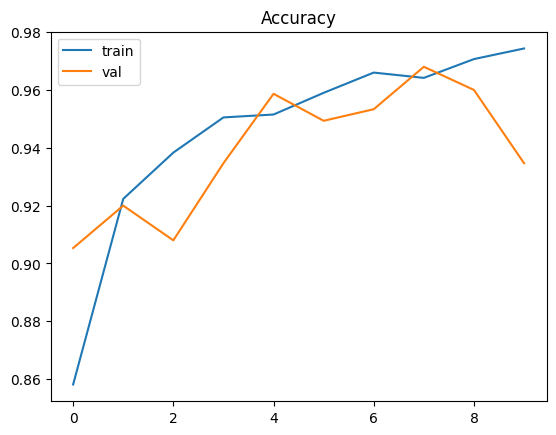

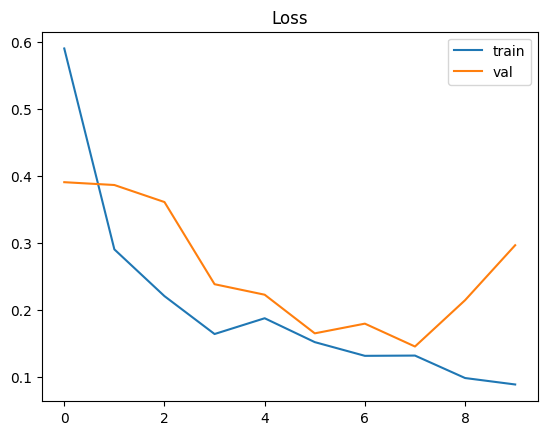

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history_fine.history['accuracy'], label='train')
plt.plot(history_fine.history['val_accuracy'], label='val')
plt.legend()
plt.title("Accuracy")
plt.show()

plt.plot(history_fine.history['loss'], label='train')
plt.plot(history_fine.history['val_loss'], label='val')
plt.legend()
plt.title("Loss")
plt.show()

In [ ]:
import numpy as np

predictions = model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)

24/24 ━━━━━━━━━━━━━━━━━━━━ 15s 387ms/step


In [ ]:
y_true = test_generator.classes
class_names = list(test_generator.class_indices.keys())

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_true, y_pred, target_names=class_names))

                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.98      1.00      0.99        50
                     Pepper__bell___healthy       0.98      0.98      0.98        50
                      Potato___Early_blight       1.00      1.00      1.00        50
                       Potato___Late_blight       1.00      0.98      0.99        50
                           Potato___healthy       0.98      0.98      0.98        50
                      Tomato_Bacterial_spot       0.98      0.96      0.97        50
                        Tomato_Early_blight       1.00      0.90      0.95        50
                         Tomato_Late_blight       0.98      1.00      0.99        50
                           Tomato_Leaf_Mold       0.98      1.00      0.99        50
                  Tomato_Septoria_leaf_spot       0.94      1.00      0.97        50
Tomato_Spider_mites_Two_spotted_spider_mite       0.96      1.00

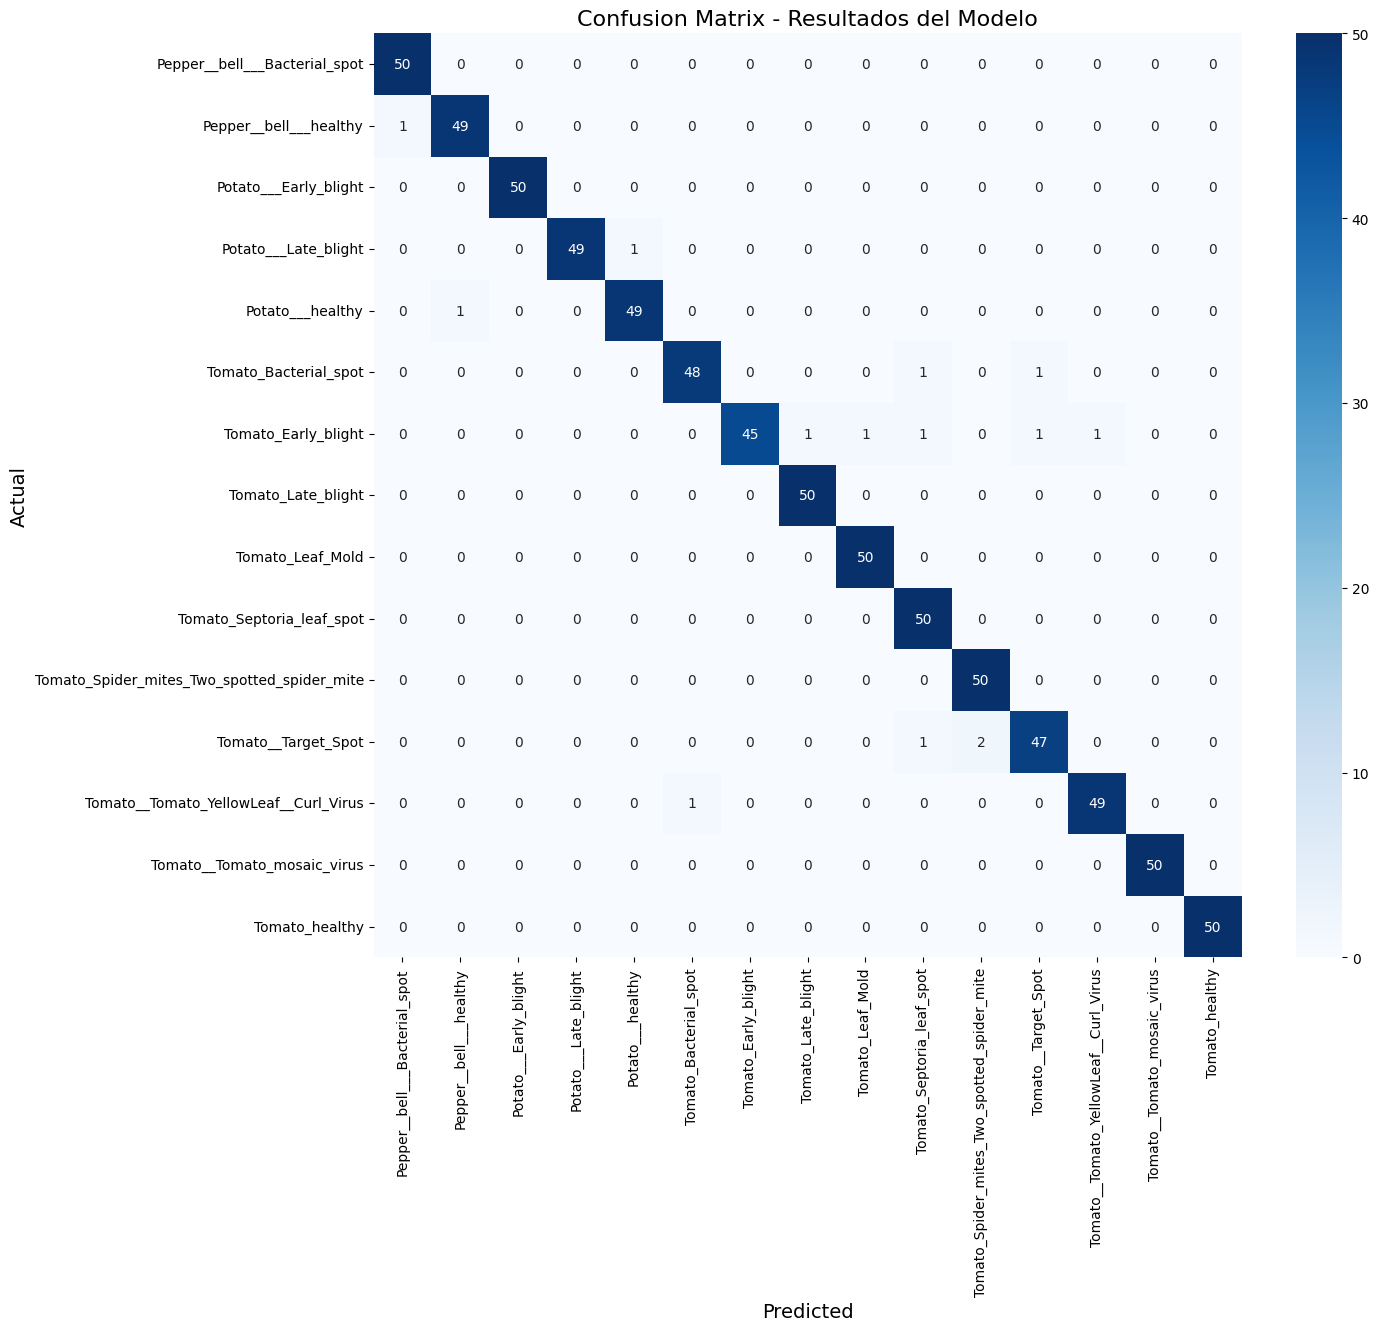

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Generamos la matriz
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(14, 12))
sns.heatmap(cm,
            annot=True,
            fmt='d',
            cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names,
            annot_kws={"size": 10})

plt.xlabel("Predicted", fontsize=14)
plt.ylabel("Actual", fontsize=14)
plt.title("Confusion Matrix - Resultados del Modelo", fontsize=16)
plt.xticks(rotation=90) # Rota las etiquetas para que se lean bien
plt.show()